In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import random

print("TensorFlow version:", tf.__version__)

print("GPU available:")
print(tf.config.list_physical_devices('GPU'))

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

TensorFlow version: 2.20.0
GPU available:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile
import os

zip_path = "/content/data.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    file_list = zip_ref.namelist()

print("Total items inside ZIP:", len(file_list))

print("\nFirst 30 items:")
for item in file_list[:30]:
    print(item)

Total items inside ZIP: 51936

First 30 items:
Meta/
Meta/.~lock.ClassesInformation.ods#
Meta/.~lock.ClassesInformationStrong.ods#
Meta/0.png
Meta/1.png
Meta/10.png
Meta/11.png
Meta/12.png
Meta/13.png
Meta/14.png
Meta/15.png
Meta/16.png
Meta/17.png
Meta/18.png
Meta/19.png
Meta/2.png
Meta/20.png
Meta/21.png
Meta/22.png
Meta/23.png
Meta/24.png
Meta/25.png
Meta/26.png
Meta/27.png
Meta/28.png
Meta/29.png
Meta/3.png
Meta/30.png
Meta/31.png
Meta/32.png


In [ ]:
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    top_level = set()

    for item in zip_ref.namelist():
        parts = item.split('/')
        if parts[0]:
            top_level.add(parts[0])

print("Main folders/files:")
for item in sorted(top_level):
    print(item)

Main folders/files:
Meta
Meta.csv
README.md
Test
Test.csv
Train
Train.csv
signnames.csv


In [ ]:
import pandas as pd

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    with zip_ref.open('Train.csv') as f:
        train_df = pd.read_csv(f)

print(train_df.shape)
print(train_df.head())
print(train_df.columns.tolist())

(39209, 8)
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId  \
0     27      26       5       5      22      20       20   
1     28      27       5       6      23      22       20   
2     29      26       6       5      24      21       20   
3     28      27       5       6      23      22       20   
4     28      26       5       5      23      21       20   

                             Path  
0  Train/20/00020_00000_00000.png  
1  Train/20/00020_00000_00001.png  
2  Train/20/00020_00000_00002.png  
3  Train/20/00020_00000_00003.png  
4  Train/20/00020_00000_00004.png  
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']


In [ ]:
print("Number of classes:", train_df["ClassId"].nunique())
print("Class IDs:", sorted(train_df["ClassId"].unique()))

Number of classes: 43
Class IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42)]


In [ ]:
class_counts = train_df["ClassId"].value_counts().sort_index()

print(class_counts)
print("\nMinimum images:", class_counts.min())
print("Maximum images:", class_counts.max())

ClassId
0      210
1     2220
2     2250
3     1410
4     1980
5     1860
6      420
7     1440
8     1410
9     1470
10    2010
11    1320
12    2100
13    2160
14     780
15     630
16     420
17    1110
18    1200
19     210
20     360
21     330
22     390
23     510
24     270
25    1500
26     600
27     240
28     540
29     270
30     450
31     780
32     240
33     689
34     420
35    1200
36     390
37     210
38    2070
39     300
40     360
41     240
42     240
Name: count, dtype: int64

Minimum images: 210
Maximum images: 2250


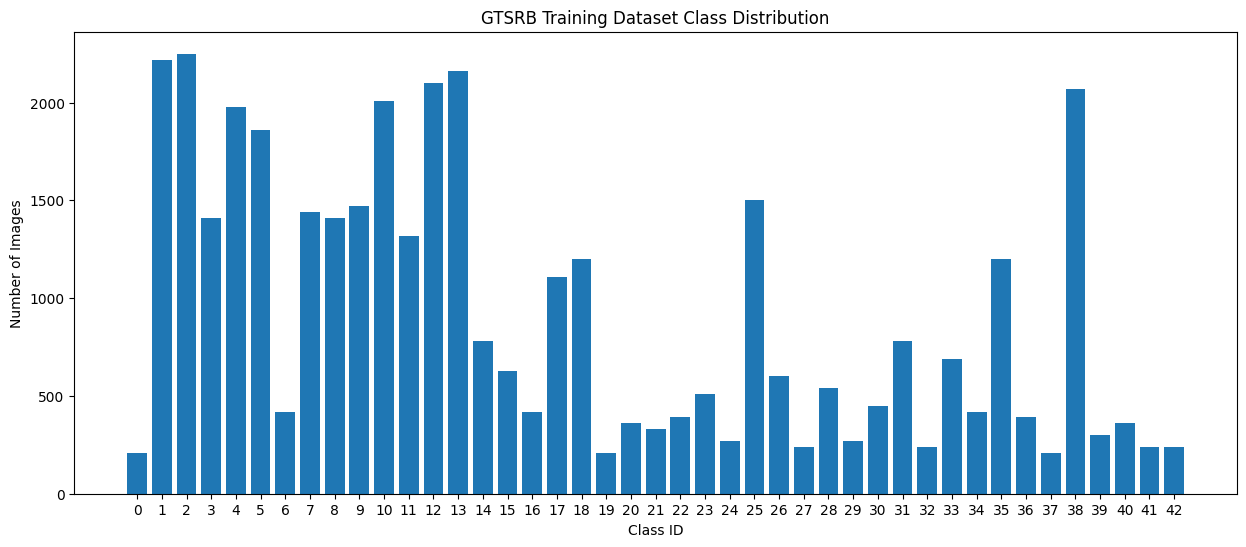

In [ ]:
plt.figure(figsize=(15, 6))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.title("GTSRB Training Dataset Class Distribution")
plt.xticks(range(43))
plt.show()

In [ ]:
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    with zip_ref.open('signnames.csv') as f:
        signnames_df = pd.read_csv(f)

print(signnames_df)


    ClassId                                           SignName
0         0                               Speed limit (20km/h)
1         1                               Speed limit (30km/h)
2         2                               Speed limit (50km/h)
3         3                               Speed limit (60km/h)
4         4                               Speed limit (70km/h)
5         5                               Speed limit (80km/h)
6         6                        End of speed limit (80km/h)
7         7                              Speed limit (100km/h)
8         8                              Speed limit (120km/h)
9         9                                         No passing
10       10       No passing for vehicles over 3.5 metric tons
11       11              Right-of-way at the next intersection
12       12                                      Priority road
13       13                                              Yield
14       14                                            

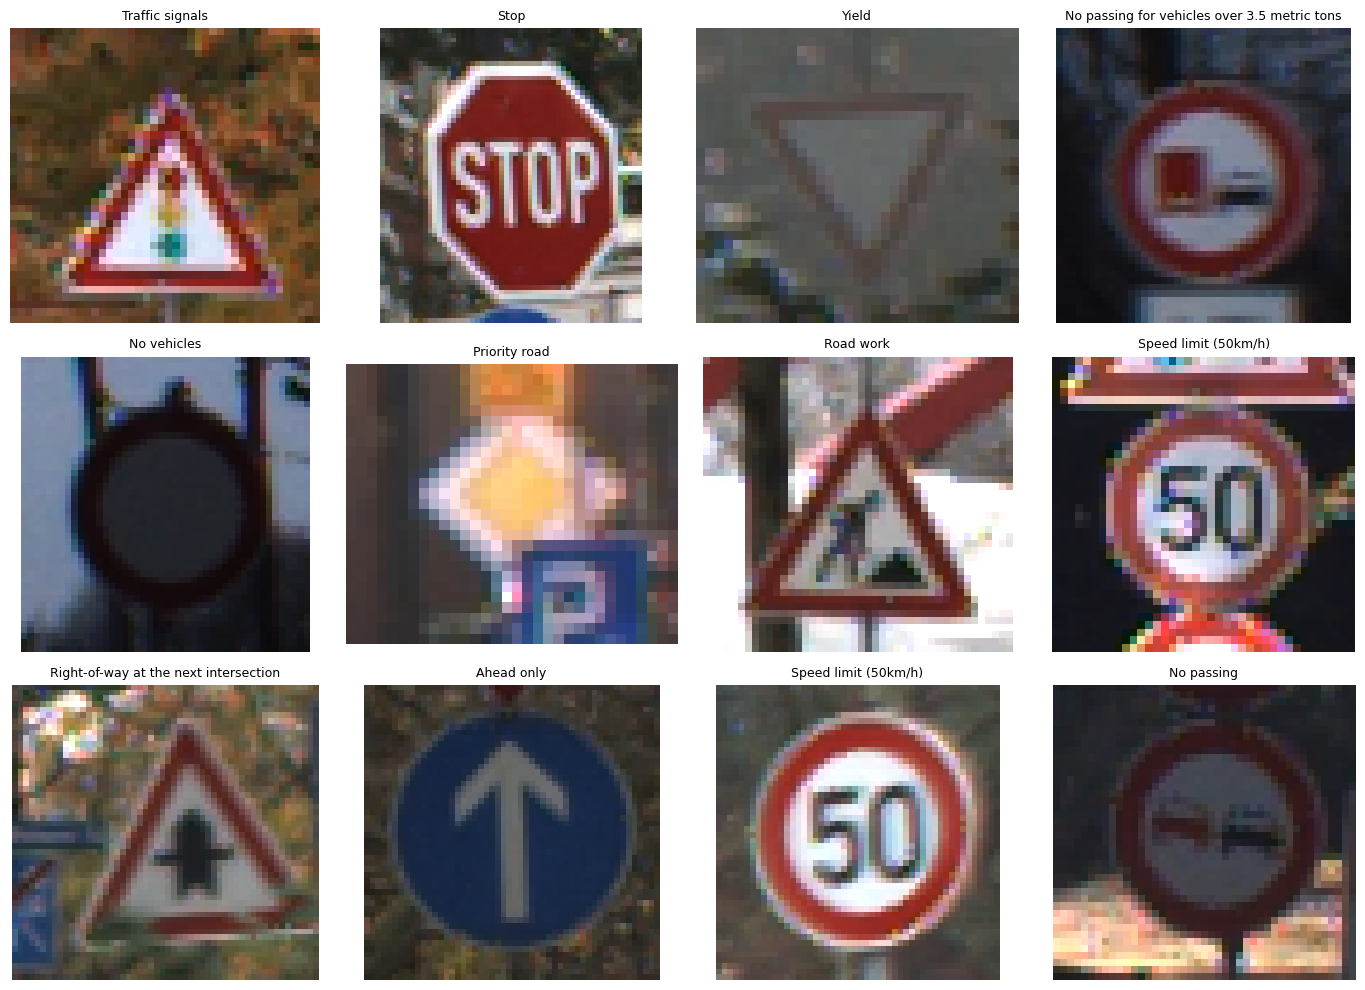

In [ ]:
import random
from PIL import Image
from io import BytesIO

sample_df = train_df.sample(12, random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
        image_data = zip_ref.read(row["Path"])
        image = Image.open(BytesIO(image_data))

        ax.imshow(image)
        ax.set_title(signnames_df.iloc[row["ClassId"]]["SignName"], fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    random_state=SEED,
    stratify=train_df["ClassId"]
)

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Total:", len(train_data) + len(val_data))

Training images: 31367
Validation images: 7842
Total: 39209


In [ ]:
distribution = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Official Test"],
    "Images": [len(train_data), len(val_data), 12630],
})

distribution["Percentage"] = (
    distribution["Images"] / distribution["Images"].sum() * 100
).round(2)

print(distribution)

         Dataset  Images  Percentage
0       Training   31367       60.51
1     Validation    7842       15.13
2  Official Test   12630       24.36


In [ ]:
train_distribution = train_data["ClassId"].value_counts(normalize=True).sort_index()
val_distribution = val_data["ClassId"].value_counts(normalize=True).sort_index()

comparison = pd.DataFrame({
    "Training %": (train_distribution * 100).round(2),
    "Validation %": (val_distribution * 100).round(2)
})

print(comparison)

         Training %  Validation %
ClassId                          
0              0.54          0.54
1              5.66          5.66
2              5.74          5.74
3              3.60          3.60
4              5.05          5.05
5              4.74          4.74
6              1.07          1.07
7              3.67          3.67
8              3.60          3.60
9              3.75          3.75
10             5.13          5.13
11             3.37          3.37
12             5.36          5.36
13             5.51          5.51
14             1.99          1.99
15             1.61          1.61
16             1.07          1.07
17             2.83          2.83
18             3.06          3.06
19             0.54          0.54
20             0.92          0.92
21             0.84          0.84
22             0.99          0.99
23             1.30          1.30
24             0.69          0.69
25             3.83          3.83
26             1.53          1.53
27            

In [ ]:
IMG_SIZE = (64, 64)
BATCH_SIZE = 64

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(0.08, 0.08)
])

In [ ]:
import os

extract_path = "/content/GTSRB"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    train_files = [f for f in zip_ref.namelist() if f.startswith("Train/")]
    zip_ref.extractall(extract_path, train_files)

print("Training images extracted:", len(train_files))
print("Location:", extract_path)

Training images extracted: 39253
Location: /content/GTSRB


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_paths = [os.path.join("/content/GTSRB", p) for p in train_data["Path"]]
val_paths = [os.path.join("/content/GTSRB", p) for p in val_data["Path"]]

train_labels = train_data["ClassId"].values
val_labels = val_data["ClassId"].values

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.shuffle(len(train_paths), seed=SEED)
train_ds = train_ds.map(load_image, num_parallel_calls=AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds = val_ds.map(load_image, num_parallel_calls=AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training batches: 491
Validation batches: 123


In [ ]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())
print("First 10 labels:", labels[:10].numpy())

Image batch shape: (64, 64, 64, 3)
Label batch shape: (64,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [12 25 15 38 16  1 30  9  3 35]


In [ ]:
from tensorflow.keras import layers, models, regularizers

baseline_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),
    layers.Dropout(0.4),

    layers.Dense(43, activation="softmax")
])

baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,202,603 (8.40 MB)

 Trainable params: 2,202,155 (8.40 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.20.0


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

print("TensorFlow:", tf.__version__)
print("Imports ready")

TensorFlow: 2.20.0
Imports ready


In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.4203 - loss: 2.1343 - val_accuracy: 0.6598 - val_loss: 1.0945 - learning_rate: 0.0010
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 35s 34ms/step - accuracy: 0.7478 - loss: 0.8556 - val_accuracy: 0.9064 - val_loss: 0.3750 - learning_rate: 0.0010
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step - accuracy: 0.8763 - loss: 0.4843 - val_accuracy: 0.9685 - val_loss: 0.2137 - learning_rate: 0.0010
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 32ms/step - accuracy: 0.9273 - loss: 0.3544 - val_accuracy: 0.9809 - val_loss: 0.1879 - learning_rate: 0.0010
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 33ms/step - accuracy: 0.9448 - loss: 0.3142 - val_accuracy: 0.9936 - val_loss: 0.1628 - learning_rate: 0.0010
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.9527 - loss: 0.3075 - val_accuracy: 0.9904 - val_loss: 0.1883 - learning_rate: 0.0010
Epoch 7/20
489/491 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9556 - lo

Using: history


,Metric,Value
0,Best Epoch,20.000000
1,Training Accuracy,0.993879
2,Validation Accuracy,0.999235
3,Training Error,0.006121
4,Validation Error,0.000765
5,Bias Estimate,0.006121
6,Variance Estimate,0.005356
7,Accuracy Gap,0.005356


Bias Estimate: 0.61%
Variance Estimate: 0.54%


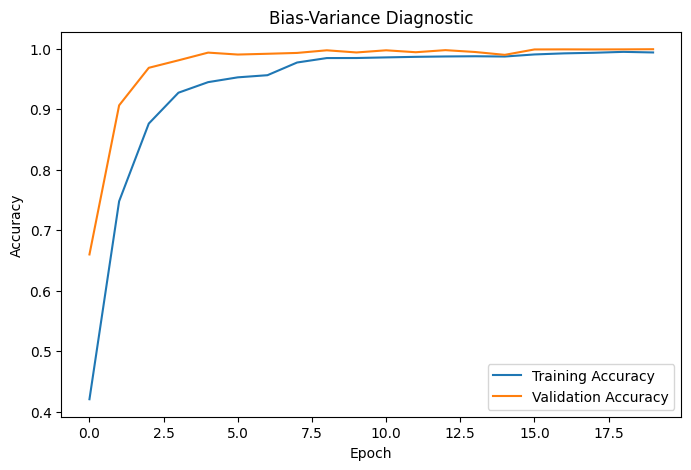

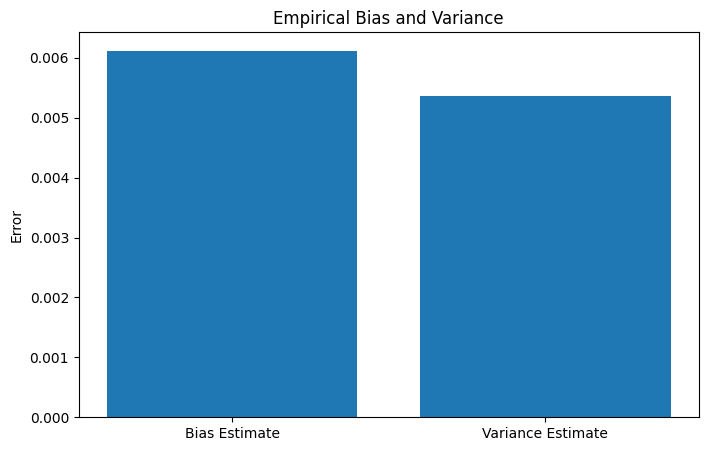

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

history_vars = [
    "history",
    "train_history",
    "training_history",
    "cnn_history",
    "model_history",
    "history_cnn",
    "history_model"
]

h = None

for name in history_vars:
    if name in globals():
        obj = globals()[name]
        if hasattr(obj, "history"):
            h = obj.history
            print("Using:", name)
            break
        if isinstance(obj, dict):
            h = obj
            print("Using:", name)
            break

if h is None:
    print("Training history is not currently available.")
    print("This cell is ready to run after the final training cell.")
else:
    acc_key = next((k for k in h if k in ["accuracy", "categorical_accuracy", "sparse_categorical_accuracy"]), None)
    val_acc_key = next((k for k in h if k in ["val_accuracy", "val_categorical_accuracy", "val_sparse_categorical_accuracy"]), None)

    if acc_key is None or val_acc_key is None:
        print("Accuracy history was not found.")
        print("Available metrics:", list(h.keys()))
    else:
        train_acc = np.array(h[acc_key])
        val_acc = np.array(h[val_acc_key])

        train_error = 1 - train_acc
        val_error = 1 - val_acc

        best_epoch = np.argmax(val_acc)
        bias_estimate = train_error[best_epoch]
        variance_estimate = abs(val_error[best_epoch] - train_error[best_epoch])

        results = pd.DataFrame({
            "Metric": [
                "Best Epoch",
                "Training Accuracy",
                "Validation Accuracy",
                "Training Error",
                "Validation Error",
                "Bias Estimate",
                "Variance Estimate",
                "Accuracy Gap"
            ],
            "Value": [
                best_epoch + 1,
                train_acc[best_epoch],
                val_acc[best_epoch],
                train_error[best_epoch],
                val_error[best_epoch],
                bias_estimate,
                variance_estimate,
                abs(train_acc[best_epoch] - val_acc[best_epoch])
            ]
        })

        display(results)

        print(f"Bias Estimate: {bias_estimate*100:.2f}%")
        print(f"Variance Estimate: {variance_estimate*100:.2f}%")

        plt.figure(figsize=(8,5))
        plt.plot(train_acc, label="Training Accuracy")
        plt.plot(val_acc, label="Validation Accuracy")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Bias-Variance Diagnostic")
        plt.legend()
        plt.show()

        plt.figure(figsize=(8,5))
        plt.bar(
            ["Bias Estimate", "Variance Estimate"],
            [bias_estimate, variance_estimate]
        )
        plt.ylabel("Error")
        plt.title("Empirical Bias and Variance")
        plt.show()

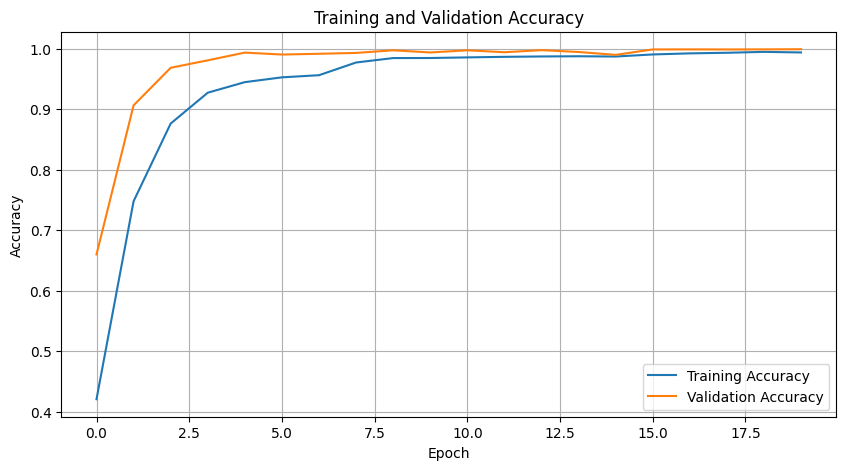

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

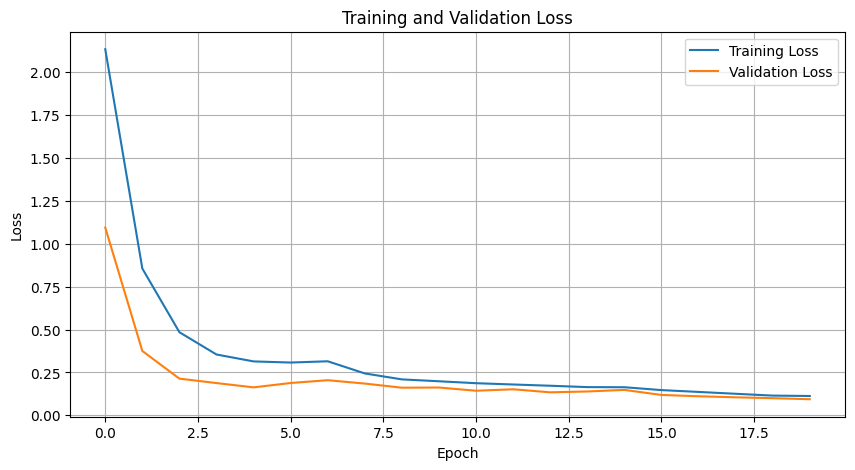

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import zipfile
import os

zip_path = "/content/data.zip"
extract_path = "/content/GTSRB"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    test_files = [f for f in zip_ref.namelist() if f.startswith("Test/")]
    zip_ref.extractall(extract_path, members=test_files)

print("Test images extracted")
print("Test folder:", os.path.join(extract_path, "Test"))

Test images extracted
Test folder: /content/GTSRB/Test


In [ ]:
import zipfile

zip_path = "/content/data.zip"
extract_path = "/content/GTSRB"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extract("Test.csv", extract_path)

print("Test.csv extracted")
print("/content/GTSRB/Test.csv")

Test.csv extracted
/content/GTSRB/Test.csv


In [ ]:
test_df = pd.read_csv("/content/GTSRB/Test.csv")

print("Test dataset shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
print(test_df.head())

Test dataset shape: (12630, 8)
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']
   Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId            Path
0     53      54       6       5      48      49       16  Test/00000.png
1     42      45       5       5      36      40        1  Test/00001.png
2     48      52       6       6      43      47       38  Test/00002.png
3     27      29       5       5      22      24       33  Test/00003.png
4     60      57       5       5      55      52       11  Test/00004.png


In [ ]:
test_paths = test_df["Path"].apply(lambda x: os.path.join("/content/GTSRB", x)).values
test_labels = test_df["ClassId"].values

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Test batches: 198


In [ ]:
test_loss, test_accuracy = baseline_model.evaluate(
    test_ds,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

198/198 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9784 - loss: 0.2110
Test Loss: 0.21100784838199615
Test Accuracy: 0.978384792804718


In [ ]:
import numpy as np

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = baseline_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("True labels:", y_true.shape)
print("Predictions:", y_pred.shape)
print("Probabilities:", y_prob.shape)

198/198 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step
True labels: (12630,)
Predictions: (12630,)
Probabilities: (12630, 43)


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

accuracy = accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

precision_weighted = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall: {recall_macro:.4f}")
print(f"Macro F1-score: {f1_macro:.4f}")
print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall: {recall_weighted:.4f}")
print(f"Weighted F1-score: {f1_weighted:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, zero_division=0))

Accuracy: 0.9784
Macro Precision: 0.9755
Macro Recall: 0.9665
Macro F1-score: 0.9682
Weighted Precision: 0.9797
Weighted Recall: 0.9784
Weighted F1-score: 0.9780

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        60
           1       0.96      1.00      0.98       720
           2       0.98      0.99      0.98       750
           3       1.00      0.99      0.99       450
           4       1.00      0.96      0.98       660
           5       0.97      0.99      0.98       630
           6       0.97      0.94      0.96       150
           7       1.00      1.00      1.00       450
           8       0.98      0.99      0.99       450
           9       1.00      0.99      1.00       480
          10       1.00      1.00      1.00       660
          11       1.00      1.00      1.00       420
          12       1.00      0.93      0.96       690
          13       0.94      1.00      0.97       720
   

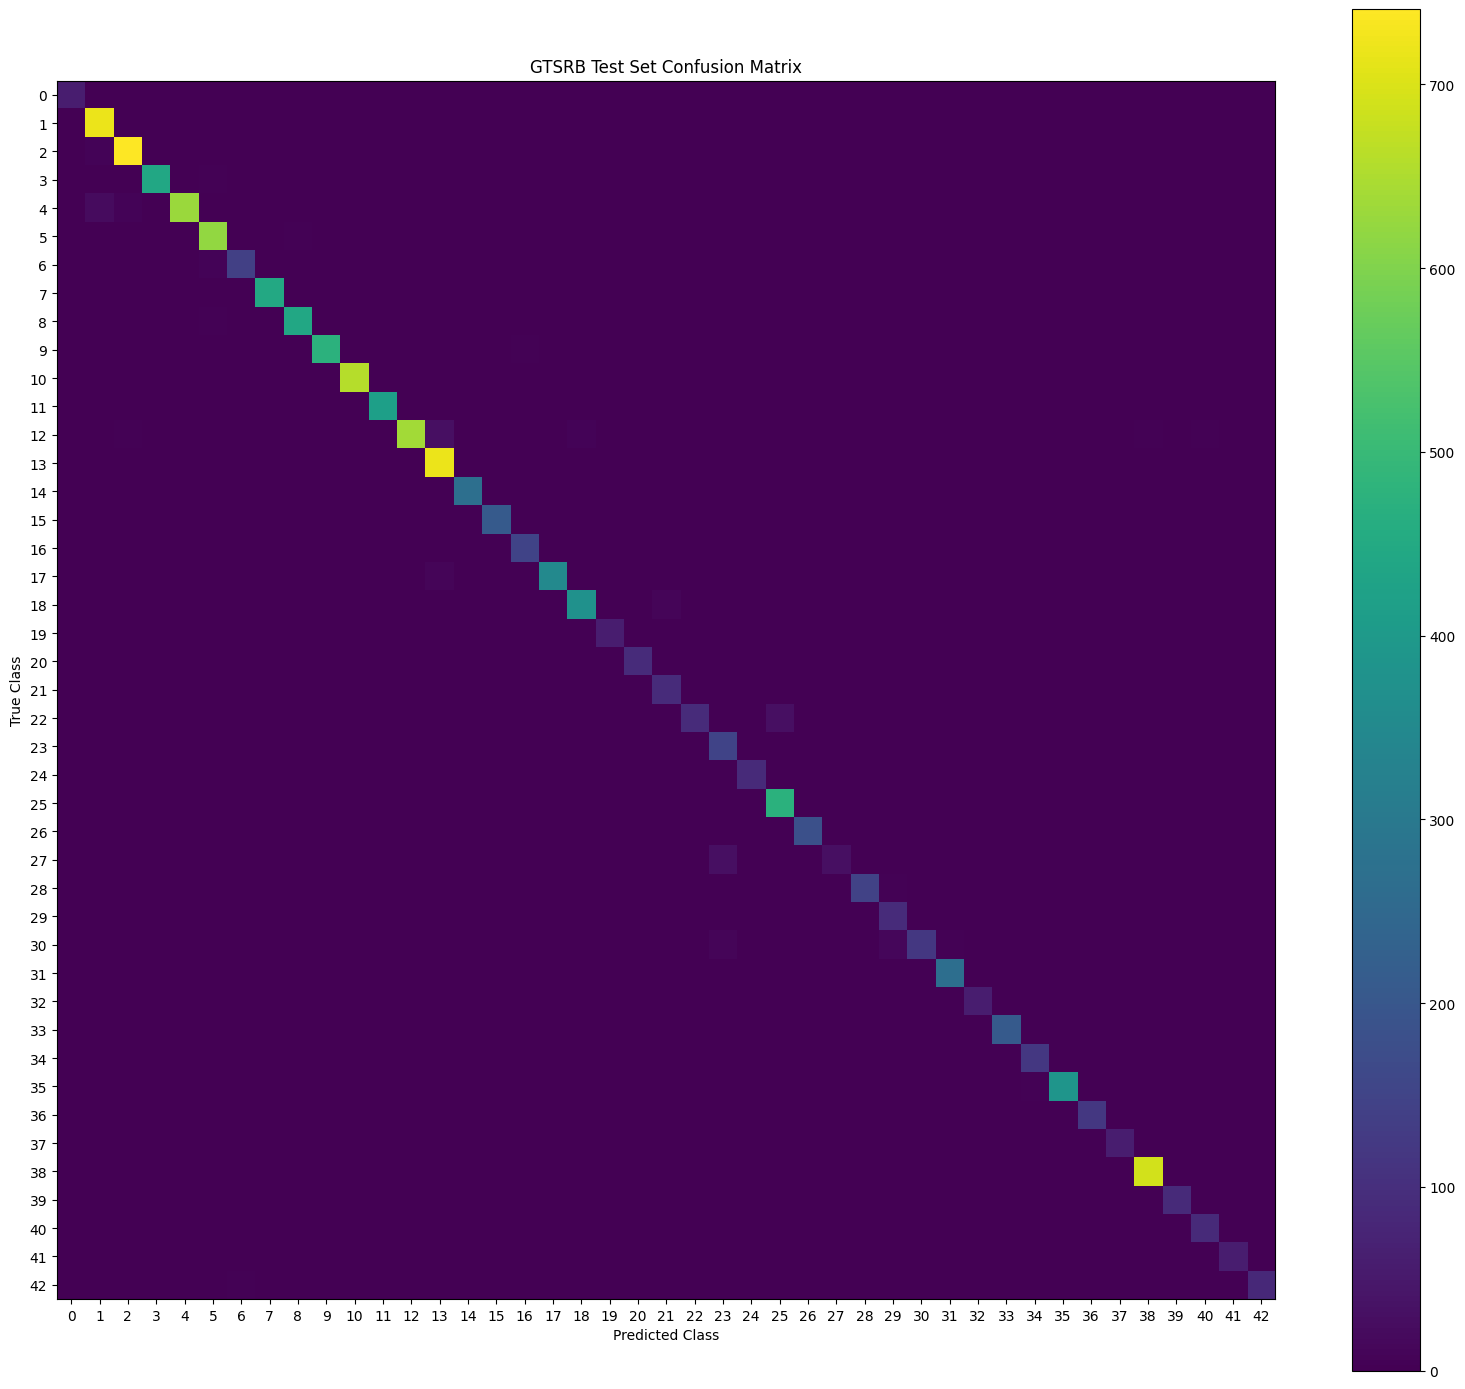

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))
plt.imshow(cm)
plt.colorbar()
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("GTSRB Test Set Confusion Matrix")
plt.xticks(range(43))
plt.yticks(range(43))
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

rows, cols = np.where(cm_off > 0)

mistakes = sorted(
    [(cm_off[r, c], r, c) for r, c in zip(rows, cols)],
    reverse=True
)

print("Top 15 misclassifications:\n")

for count, true_class, predicted_class in mistakes[:15]:
    print(
        f"True Class {true_class} -> Predicted Class {predicted_class}: {count} images"
    )

Top 15 misclassifications:

True Class 27 -> Predicted Class 23: 30 images
True Class 12 -> Predicted Class 13: 30 images
True Class 22 -> Predicted Class 25: 29 images
True Class 4 -> Predicted Class 1: 21 images
True Class 30 -> Predicted Class 29: 14 images
True Class 17 -> Predicted Class 13: 11 images
True Class 18 -> Predicted Class 21: 10 images
True Class 30 -> Predicted Class 23: 9 images
True Class 6 -> Predicted Class 5: 8 images
True Class 2 -> Predicted Class 1: 8 images
True Class 12 -> Predicted Class 18: 6 images
True Class 4 -> Predicted Class 2: 6 images
True Class 28 -> Predicted Class 29: 5 images
True Class 12 -> Predicted Class 2: 5 images
True Class 8 -> Predicted Class 5: 5 images


In [ ]:
with zipfile.ZipFile("/content/data.zip", "r") as zip_ref:
    zip_ref.extract("signnames.csv", "/content/GTSRB")

signnames_df = pd.read_csv("/content/GTSRB/signnames.csv")

class_names = dict(
    zip(signnames_df["ClassId"], signnames_df["SignName"])
)

for count, true_class, predicted_class in mistakes[:15]:
    print(
        f"{count} errors | "
        f"{true_class}: {class_names[true_class]} -> "
        f"{predicted_class}: {class_names[predicted_class]}"
    )

30 errors | 27: Pedestrians -> 23: Slippery road
30 errors | 12: Priority road -> 13: Yield
29 errors | 22: Bumpy road -> 25: Road work
21 errors | 4: Speed limit (70km/h) -> 1: Speed limit (30km/h)
14 errors | 30: Beware of ice/snow -> 29: Bicycles crossing
11 errors | 17: No entry -> 13: Yield
10 errors | 18: General caution -> 21: Double curve
9 errors | 30: Beware of ice/snow -> 23: Slippery road
8 errors | 6: End of speed limit (80km/h) -> 5: Speed limit (80km/h)
8 errors | 2: Speed limit (50km/h) -> 1: Speed limit (30km/h)
6 errors | 12: Priority road -> 18: General caution
6 errors | 4: Speed limit (70km/h) -> 2: Speed limit (50km/h)
5 errors | 28: Children crossing -> 29: Bicycles crossing
5 errors | 12: Priority road -> 2: Speed limit (50km/h)
5 errors | 8: Speed limit (120km/h) -> 5: Speed limit (80km/h)


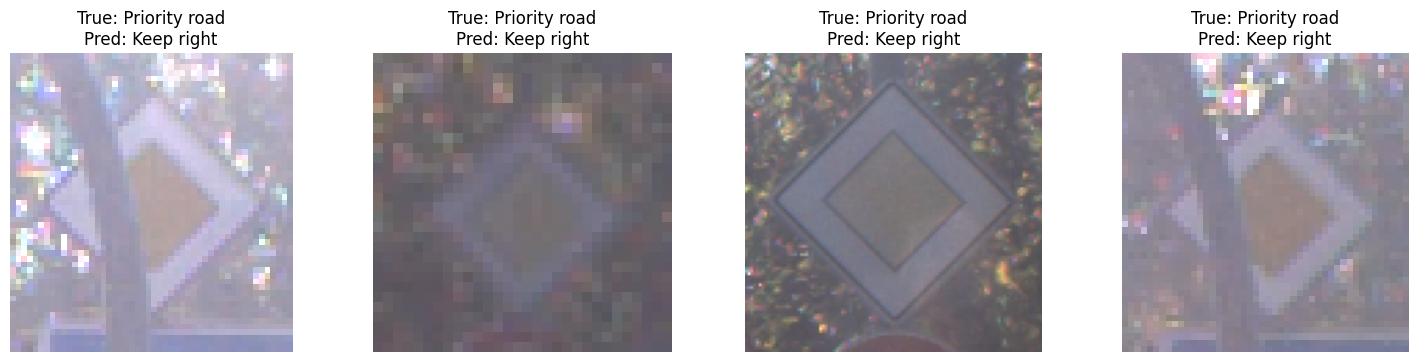

In [ ]:
target_true = 12
target_pred = 38

indices = np.where(
    (y_true == target_true) & (y_pred == target_pred)
)[0]

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices[:12]):
    image_path = test_paths[idx]
    image = tf.io.decode_png(tf.io.read_file(image_path), channels=3)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"True: {class_names[target_true]}\nPred: {class_names[target_pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
target_true = 27
target_pred = 29

indices = np.where(
    (y_true == target_true) & (y_pred == target_pred)
)[0]

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices[:12]):
    image_path = test_paths[idx]
    image = tf.io.decode_png(tf.io.read_file(image_path), channels=3)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"True: {class_names[target_true]}\nPred: {class_names[target_pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1500x1000 with 0 Axes>

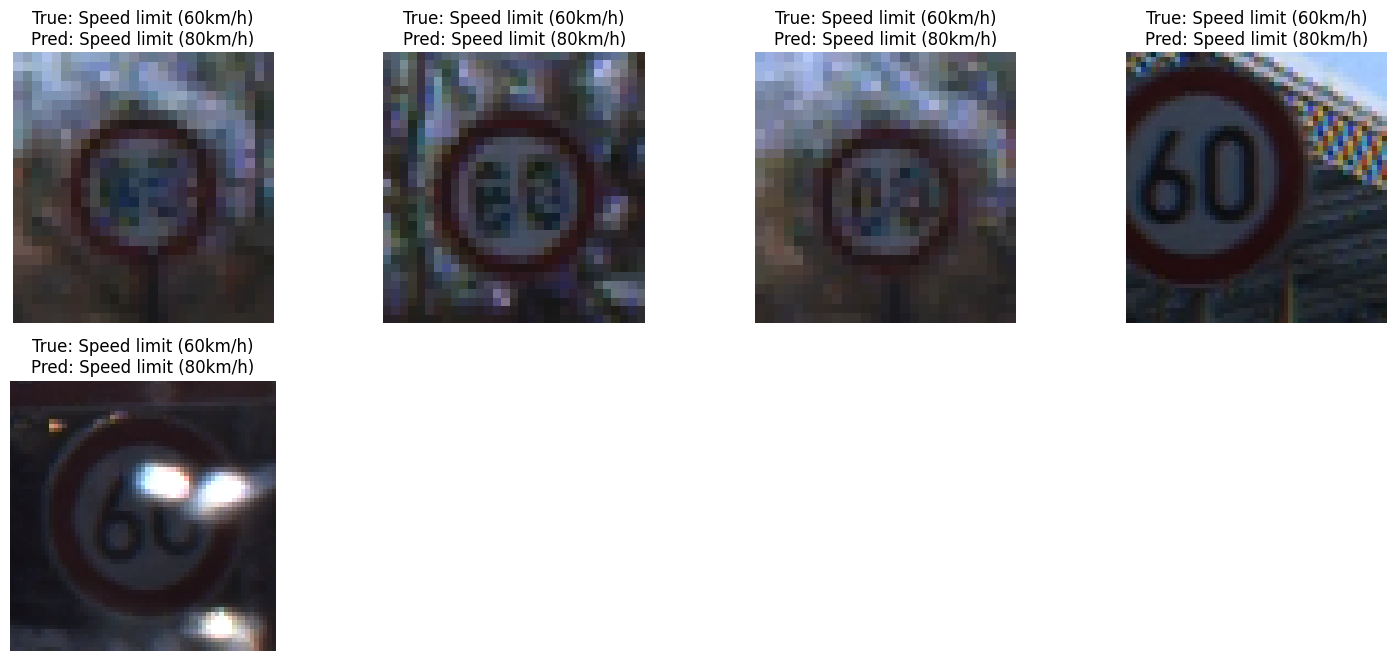

In [ ]:
target_true = 3
target_pred = 5

indices = np.where(
    (y_true == target_true) & (y_pred == target_pred)
)[0]

plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices[:12]):
    image_path = test_paths[idx]
    image = tf.io.decode_png(tf.io.read_file(image_path), channels=3)

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(f"True: {class_names[target_true]}\nPred: {class_names[target_pred]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def load_roi_image(path, label, x1, y1, x2, y2):
    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.crop_to_bounding_box(
        image,
        y1,
        x1,
        y2 - y1,
        x2 - x1
    )
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

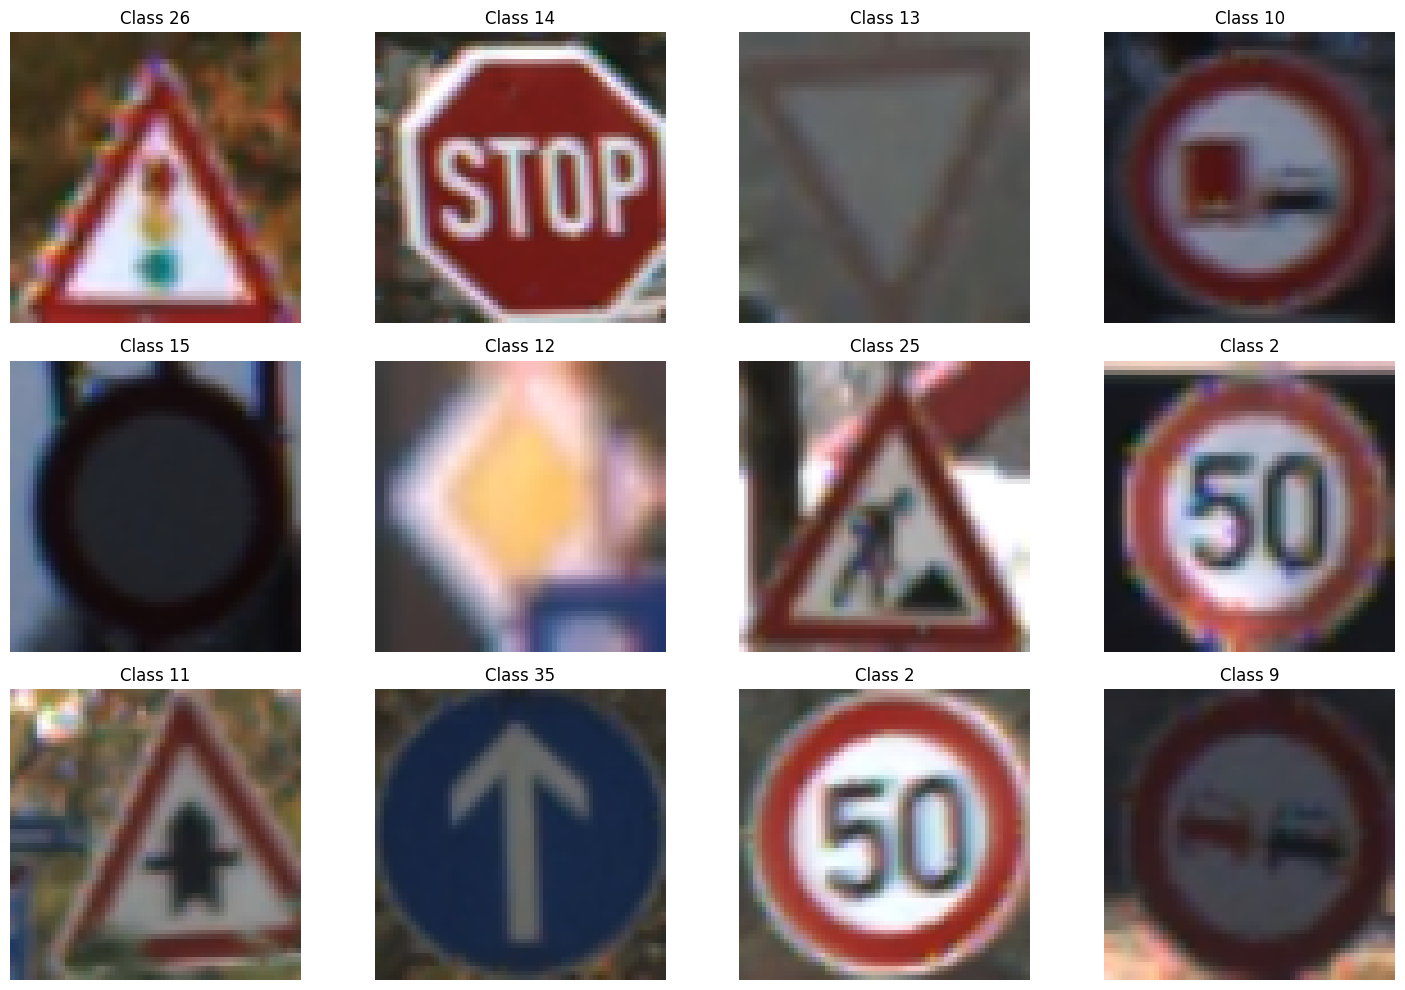

In [ ]:
sample_df = train_df.sample(12, random_state=42).reset_index(drop=True)

plt.figure(figsize=(15, 10))

for i in range(12):
    row = sample_df.iloc[i]
    path = os.path.join("/content/GTSRB", row["Path"])

    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=3)

    roi = tf.image.crop_to_bounding_box(
        image,
        int(row["Roi.Y1"]),
        int(row["Roi.X1"]),
        int(row["Roi.Y2"] - row["Roi.Y1"]),
        int(row["Roi.X2"] - row["Roi.X1"])
    )

    roi = tf.image.resize(roi, IMG_SIZE)
    roi = tf.cast(roi, tf.float32) / 255.0

    plt.subplot(3, 4, i + 1)
    plt.imshow(roi)
    plt.title(f"Class {row['ClassId']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
train_roi_paths = train_data["Path"].apply(
    lambda x: os.path.join("/content/GTSRB", x)
).values

train_roi_labels = train_data["ClassId"].values

val_roi_paths = val_data["Path"].apply(
    lambda x: os.path.join("/content/GTSRB", x)
).values

val_roi_labels = val_data["ClassId"].values

train_roi_x1 = train_data["Roi.X1"].values.astype(np.int32)
train_roi_y1 = train_data["Roi.Y1"].values.astype(np.int32)
train_roi_x2 = train_data["Roi.X2"].values.astype(np.int32)
train_roi_y2 = train_data["Roi.Y2"].values.astype(np.int32)

val_roi_x1 = val_data["Roi.X1"].values.astype(np.int32)
val_roi_y1 = val_data["Roi.Y1"].values.astype(np.int32)
val_roi_x2 = val_data["Roi.X2"].values.astype(np.int32)
val_roi_y2 = val_data["Roi.Y2"].values.astype(np.int32)

train_roi_ds = tf.data.Dataset.from_tensor_slices(
    (
        train_roi_paths,
        train_roi_labels,
        train_roi_x1,
        train_roi_y1,
        train_roi_x2,
        train_roi_y2
    )
)

val_roi_ds = tf.data.Dataset.from_tensor_slices(
    (
        val_roi_paths,
        val_roi_labels,
        val_roi_x1,
        val_roi_y1,
        val_roi_x2,
        val_roi_y2
    )
)

train_roi_ds = train_roi_ds.shuffle(
    len(train_data),
    seed=SEED,
    reshuffle_each_iteration=True
)

train_roi_ds = train_roi_ds.map(
    load_roi_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_roi_ds = val_roi_ds.map(
    load_roi_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_roi_ds = train_roi_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_roi_ds = val_roi_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("ROI training batches:", tf.data.experimental.cardinality(train_roi_ds).numpy())
print("ROI validation batches:", tf.data.experimental.cardinality(val_roi_ds).numpy())

ROI training batches: 491
ROI validation batches: 123


In [ ]:
roi_images, roi_labels = next(iter(train_roi_ds))

print("ROI image batch shape:", roi_images.shape)
print("ROI label batch shape:", roi_labels.shape)
print("Pixel minimum:", tf.reduce_min(roi_images).numpy())
print("Pixel maximum:", tf.reduce_max(roi_images).numpy())
print("First 10 labels:", roi_labels[:10].numpy())

ROI image batch shape: (64, 64, 64, 3)
ROI label batch shape: (64,)
Pixel minimum: 0.0
Pixel maximum: 1.0
First 10 labels: [12 25 15 38 16  1 30  9  3 35]


In [ ]:
roi_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(0.0001)
    ),
    layers.Dropout(0.4),

    layers.Dense(43, activation="softmax")
])

roi_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

roi_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,202,603 (8.40 MB)

 Trainable params: 2,202,155 (8.40 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
roi_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

roi_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

roi_history = roi_model.fit(
    train_roi_ds,
    validation_data=val_roi_ds,
    epochs=20,
    callbacks=[roi_early_stopping, roi_reduce_lr],
    verbose=1
)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - accuracy: 0.5038 - loss: 1.7890 - val_accuracy: 0.6691 - val_loss: 1.2460 - learning_rate: 0.0010
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 35ms/step - accuracy: 0.8096 - loss: 0.6666 - val_accuracy: 0.9735 - val_loss: 0.1761 - learning_rate: 0.0010
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - accuracy: 0.8947 - loss: 0.4251 - val_accuracy: 0.9758 - val_loss: 0.1810 - learning_rate: 0.0010
Epoch 4/20
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.9160 - loss: 0.3824
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - accuracy: 0.9242 - loss: 0.3641 - val_accuracy: 0.9726 - val_loss: 0.2163 - learning_rate: 0.0010
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.9627 - loss: 0.2426 - val_accuracy: 0.9973 - val_loss: 0.1286 - learning_rate: 5.0000e-04
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.9713 -

In [ ]:
test_roi_paths = test_df["Path"].apply(
    lambda x: os.path.join("/content/GTSRB", x)
).values

test_roi_labels = test_df["ClassId"].values

test_roi_x1 = test_df["Roi.X1"].values.astype(np.int32)
test_roi_y1 = test_df["Roi.Y1"].values.astype(np.int32)
test_roi_x2 = test_df["Roi.X2"].values.astype(np.int32)
test_roi_y2 = test_df["Roi.Y2"].values.astype(np.int32)

test_roi_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_roi_paths,
        test_roi_labels,
        test_roi_x1,
        test_roi_y1,
        test_roi_x2,
        test_roi_y2
    )
)

test_roi_ds = test_roi_ds.map(
    load_roi_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_roi_ds = test_roi_ds.batch(BATCH_SIZE)
test_roi_ds = test_roi_ds.prefetch(tf.data.AUTOTUNE)

print(
    "ROI test batches:",
    tf.data.experimental.cardinality(test_roi_ds).numpy()
)

ROI test batches: 198


In [ ]:
roi_test_loss, roi_test_accuracy = roi_model.evaluate(
    test_roi_ds,
    verbose=1
)

print("ROI Test Loss:", roi_test_loss)
print("ROI Test Accuracy:", roi_test_accuracy)

198/198 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9843 - loss: 0.1374
ROI Test Loss: 0.13735288381576538
ROI Test Accuracy: 0.9843230247497559


In [ ]:
roi_y_true = np.concatenate([y.numpy() for _, y in test_roi_ds])

roi_y_prob = roi_model.predict(
    test_roi_ds,
    verbose=1
)

roi_y_pred = np.argmax(roi_y_prob, axis=1)

print("True labels:", roi_y_true.shape)
print("Predicted labels:", roi_y_pred.shape)
print("Probability matrix:", roi_y_prob.shape)

198/198 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step
True labels: (12630,)
Predicted labels: (12630,)
Probability matrix: (12630, 43)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

roi_accuracy = accuracy_score(roi_y_true, roi_y_pred)
roi_precision = precision_score(
    roi_y_true,
    roi_y_pred,
    average="macro",
    zero_division=0
)
roi_recall = recall_score(
    roi_y_true,
    roi_y_pred,
    average="macro",
    zero_division=0
)
roi_f1 = f1_score(
    roi_y_true,
    roi_y_pred,
    average="macro",
    zero_division=0
)

roi_weighted_precision = precision_score(
    roi_y_true,
    roi_y_pred,
    average="weighted",
    zero_division=0
)
roi_weighted_recall = recall_score(
    roi_y_true,
    roi_y_pred,
    average="weighted",
    zero_division=0
)
roi_weighted_f1 = f1_score(
    roi_y_true,
    roi_y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy: {roi_accuracy:.4f}")
print(f"Macro Precision: {roi_precision:.4f}")
print(f"Macro Recall: {roi_recall:.4f}")
print(f"Macro F1: {roi_f1:.4f}")
print(f"Weighted Precision: {roi_weighted_precision:.4f}")
print(f"Weighted Recall: {roi_weighted_recall:.4f}")
print(f"Weighted F1: {roi_weighted_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    roi_y_true,
    roi_y_pred,
    digits=4,
    zero_division=0
))

Accuracy: 0.9843
Macro Precision: 0.9776
Macro Recall: 0.9739
Macro F1: 0.9742
Weighted Precision: 0.9851
Weighted Recall: 0.9843
Weighted F1: 0.9842

Classification Report:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        60
           1     0.9876    0.9972    0.9924       720
           2     0.9960    0.9947    0.9953       750
           3     0.9977    0.9800    0.9888       450
           4     0.9970    0.9924    0.9947       660
           5     0.9856    0.9778    0.9817       630
           6     1.0000    0.9267    0.9619       150
           7     0.9718    0.9956    0.9835       450
           8     0.9912    0.9956    0.9933       450
           9     1.0000    1.0000    1.0000       480
          10     1.0000    0.9985    0.9992       660
          11     0.9610    0.9976    0.9790       420
          12     0.9956    0.9884    0.9920       690
          13     0.9890    0.9972    0.9931       720
          14   

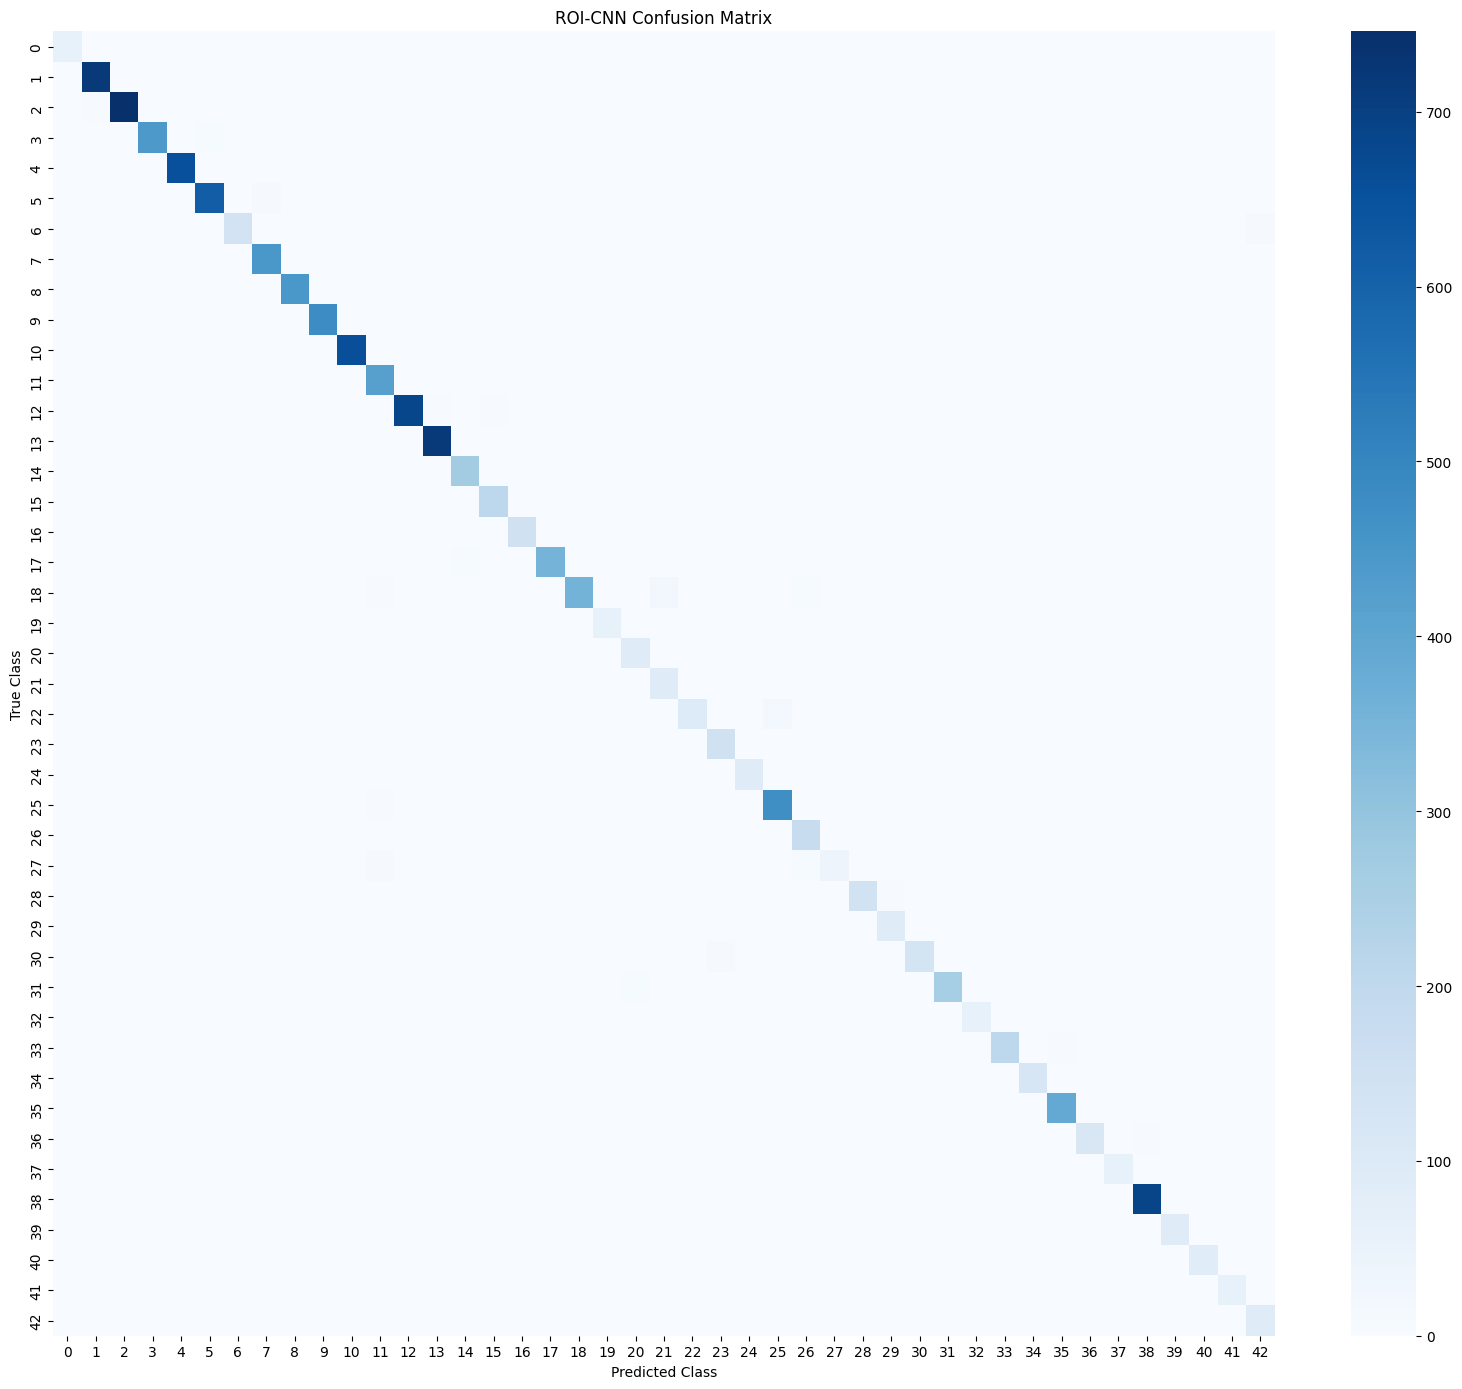

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

roi_cm = confusion_matrix(roi_y_true, roi_y_pred)

plt.figure(figsize=(16, 14))
sns.heatmap(
    roi_cm,
    cmap="Blues",
    xticklabels=range(43),
    yticklabels=range(43)
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("ROI-CNN Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

misclassified = pd.DataFrame({
    "True": roi_y_true,
    "Predicted": roi_y_pred
})

misclassified = misclassified[
    misclassified["True"] != misclassified["Predicted"]
]

top_roi_errors = (
    misclassified
    .groupby(["True", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(15)
)

sign_names = pd.read_csv("/content/GTSRB/signnames.csv")

top_roi_errors["True Sign"] = top_roi_errors["True"].map(
    dict(zip(sign_names["ClassId"], sign_names["SignName"]))
)

top_roi_errors["Predicted Sign"] = top_roi_errors["Predicted"].map(
    dict(zip(sign_names["ClassId"], sign_names["SignName"]))
)

print(top_roi_errors.to_string(index=False))

 True  Predicted  Count                   True Sign                                     Predicted Sign
   18         21     21             General caution                                       Double curve
   22         25     20                  Bumpy road                                          Road work
    6         42     10 End of speed limit (80km/h) End of no passing by vehicles over 3.5 metric tons
    5          7     10        Speed limit (80km/h)                              Speed limit (100km/h)
   30         23     10          Beware of ice/snow                                      Slippery road
   27         11      9                 Pedestrians              Right-of-way at the next intersection
    3          5      8        Speed limit (60km/h)                               Speed limit (80km/h)
   27         26      7                 Pedestrians                                    Traffic signals
   18         26      7             General caution                      

In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix
import numpy as np

roi_roc_auc = roc_auc_score(
    roi_y_true,
    roi_y_prob,
    multi_class="ovr",
    average="macro"
)

roi_cm = confusion_matrix(roi_y_true, roi_y_pred)

roi_specificities = []

for i in range(43):
    tp = roi_cm[i, i]
    fn = np.sum(roi_cm[i, :]) - tp
    fp = np.sum(roi_cm[:, i]) - tp
    tn = np.sum(roi_cm) - (tp + fn + fp)

    specificity = tn / (tn + fp)
    roi_specificities.append(specificity)

roi_macro_specificity = np.mean(roi_specificities)

print(f"Macro ROC-AUC: {roi_roc_auc:.4f}")
print(f"Macro Specificity: {roi_macro_specificity:.4f}")

Macro ROC-AUC: 0.9999
Macro Specificity: 0.9996


In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix
import numpy as np

baseline_roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

baseline_cm = confusion_matrix(y_true, y_pred)

baseline_specificities = []

for i in range(43):
    tp = baseline_cm[i, i]
    fn = np.sum(baseline_cm[i, :]) - tp
    fp = np.sum(baseline_cm[:, i]) - tp
    tn = np.sum(baseline_cm) - (tp + fn + fp)

    specificity = tn / (tn + fp)
    baseline_specificities.append(specificity)

baseline_macro_specificity = np.mean(baseline_specificities)

print(f"Baseline Macro ROC-AUC: {baseline_roc_auc:.4f}")
print(f"Baseline Macro Specificity: {baseline_macro_specificity:.4f}")

Baseline Macro ROC-AUC: 0.9998
Baseline Macro Specificity: 0.9995


In [ ]:
from tensorflow.keras import layers, models, regularizers

l1_model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l1(0.0001)
    ),
    layers.Dropout(0.4),

    layers.Dense(43, activation="softmax")
])

l1_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

l1_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,202,603 (8.40 MB)

 Trainable params: 2,202,155 (8.40 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
l1_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

l1_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

l1_history = l1_model.fit(
    train_roi_ds,
    validation_data=val_roi_ds,
    epochs=20,
    callbacks=[l1_early_stopping, l1_reduce_lr],
    verbose=1
)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 22s 38ms/step - accuracy: 0.4955 - loss: 3.6159 - val_accuracy: 0.7365 - val_loss: 2.1785 - learning_rate: 0.0010
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.8296 - loss: 1.7695 - val_accuracy: 0.9558 - val_loss: 1.4708 - learning_rate: 0.0010
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 37ms/step - accuracy: 0.9189 - loss: 1.4989 - val_accuracy: 0.9758 - val_loss: 1.2926 - learning_rate: 0.0010
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.9430 - loss: 1.3532 - val_accuracy: 0.9709 - val_loss: 1.2161 - learning_rate: 0.0010
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - accuracy: 0.9544 - loss: 1.2727 - val_accuracy: 0.9867 - val_loss: 1.1195 - learning_rate: 0.0010
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 36ms/step - accuracy: 0.9577 - loss: 1.2352 - val_accuracy: 0.9935 - val_loss: 1.0398 - learning_rate: 0.0010
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.9649 - l

In [ ]:
l1_test_loss, l1_test_accuracy = l1_model.evaluate(
    test_roi_ds,
    verbose=1
)

print("L1 Test Loss:", l1_test_loss)
print("L1 Test Accuracy:", l1_test_accuracy)

198/198 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9819 - loss: 0.3485
L1 Test Loss: 0.3484859764575958
L1 Test Accuracy: 0.98186856508255


In [ ]:
l1_y_true = np.concatenate([
    y.numpy() for _, y in test_roi_ds
])

l1_y_prob = l1_model.predict(
    test_roi_ds,
    verbose=1
)

l1_y_pred = np.argmax(l1_y_prob, axis=1)

print("True labels:", l1_y_true.shape)
print("Predicted labels:", l1_y_pred.shape)
print("Probability matrix:", l1_y_prob.shape)

198/198 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step
True labels: (12630,)
Predicted labels: (12630,)
Probability matrix: (12630, 43)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

l1_accuracy = accuracy_score(l1_y_true, l1_y_pred)

l1_precision = precision_score(
    l1_y_true,
    l1_y_pred,
    average="macro",
    zero_division=0
)

l1_recall = recall_score(
    l1_y_true,
    l1_y_pred,
    average="macro",
    zero_division=0
)

l1_f1 = f1_score(
    l1_y_true,
    l1_y_pred,
    average="macro",
    zero_division=0
)

l1_weighted_precision = precision_score(
    l1_y_true,
    l1_y_pred,
    average="weighted",
    zero_division=0
)

l1_weighted_recall = recall_score(
    l1_y_true,
    l1_y_pred,
    average="weighted",
    zero_division=0
)

l1_weighted_f1 = f1_score(
    l1_y_true,
    l1_y_pred,
    average="weighted",
    zero_division=0
)

l1_roc_auc = roc_auc_score(
    l1_y_true,
    l1_y_prob,
    multi_class="ovr",
    average="macro"
)

l1_cm = confusion_matrix(l1_y_true, l1_y_pred)

l1_specificities = []

for i in range(43):
    tp = l1_cm[i, i]
    fn = np.sum(l1_cm[i, :]) - tp
    fp = np.sum(l1_cm[:, i]) - tp
    tn = np.sum(l1_cm) - (tp + fn + fp)

    specificity = tn / (tn + fp)
    l1_specificities.append(specificity)

l1_macro_specificity = np.mean(l1_specificities)

print(f"Accuracy: {l1_accuracy:.4f}")
print(f"Macro Precision: {l1_precision:.4f}")
print(f"Macro Recall: {l1_recall:.4f}")
print(f"Macro F1: {l1_f1:.4f}")
print(f"Weighted Precision: {l1_weighted_precision:.4f}")
print(f"Weighted Recall: {l1_weighted_recall:.4f}")
print(f"Weighted F1: {l1_weighted_f1:.4f}")
print(f"Macro Specificity: {l1_macro_specificity:.4f}")
print(f"Macro ROC-AUC: {l1_roc_auc:.4f}")

Accuracy: 0.9819
Macro Precision: 0.9746
Macro Recall: 0.9726
Macro F1: 0.9728
Weighted Precision: 0.9825
Weighted Recall: 0.9819
Weighted F1: 0.9817
Macro Specificity: 0.9996
Macro ROC-AUC: 0.9999


In [ ]:
results_table = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "ROI-CNN (L2)",
        "ROI-CNN (L1)"
    ],
    "Test Accuracy": [
        0.9777513742,
        roi_accuracy,
        l1_accuracy
    ],
    "Macro Precision": [
        0.9675,
        roi_precision,
        l1_precision
    ],
    "Macro Recall": [
        0.9678,
        roi_recall,
        l1_recall
    ],
    "Macro F1": [
        0.9660,
        roi_f1,
        l1_f1
    ],
    "Macro Specificity": [
        baseline_macro_specificity,
        roi_macro_specificity,
        l1_macro_specificity
    ],
    "Macro ROC-AUC": [
        baseline_roc_auc,
        roi_roc_auc,
        l1_roc_auc
    ],
    "Test Loss": [
        0.2104007453,
        roi_test_loss,
        l1_test_loss
    ],
    "Parameters": [
        2202603,
        2202603,
        2202603
    ]
})

print(results_table.to_string(index=False))

       Model  Test Accuracy  Macro Precision  Macro Recall  Macro F1  Macro Specificity  Macro ROC-AUC  Test Loss  Parameters
Baseline CNN       0.977751         0.967500      0.967800  0.966000           0.999479       0.999785   0.210401     2202603
ROI-CNN (L2)       0.984323         0.977581      0.973887  0.974174           0.999625       0.999944   0.137353     2202603
ROI-CNN (L1)       0.981869         0.974595      0.972560  0.972760           0.999564       0.999871   0.348486     2202603


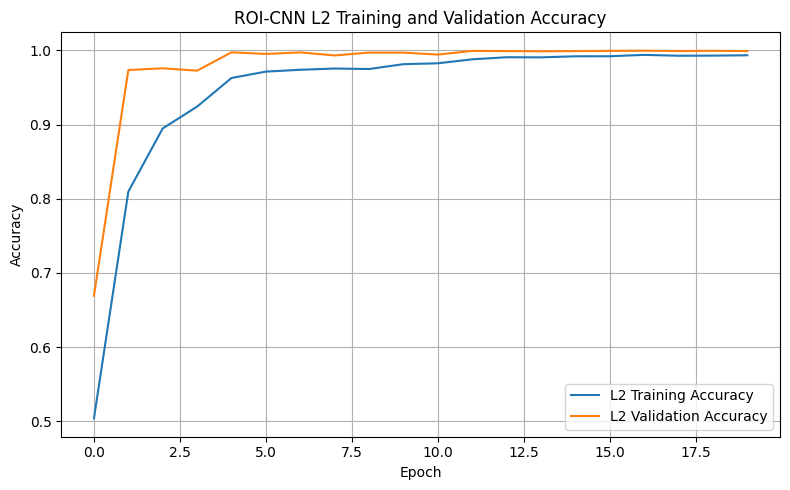

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    roi_history.history["accuracy"],
    label="L2 Training Accuracy"
)

plt.plot(
    roi_history.history["val_accuracy"],
    label="L2 Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ROI-CNN L2 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

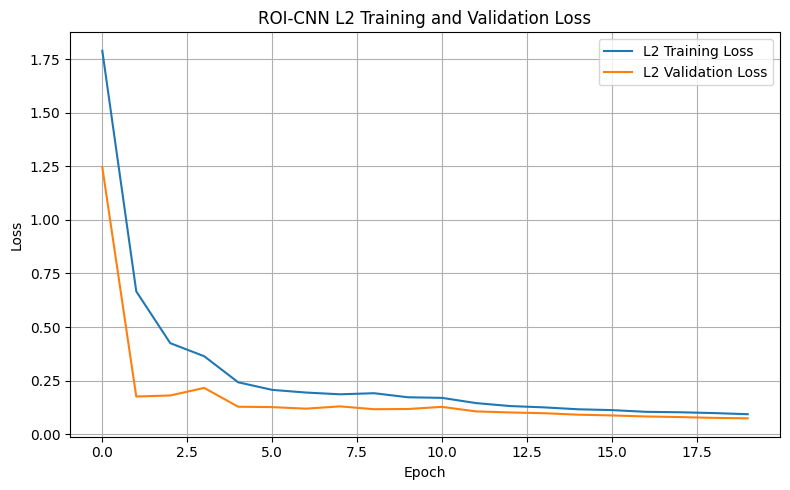

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    roi_history.history["loss"],
    label="L2 Training Loss"
)

plt.plot(
    roi_history.history["val_loss"],
    label="L2 Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ROI-CNN L2 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

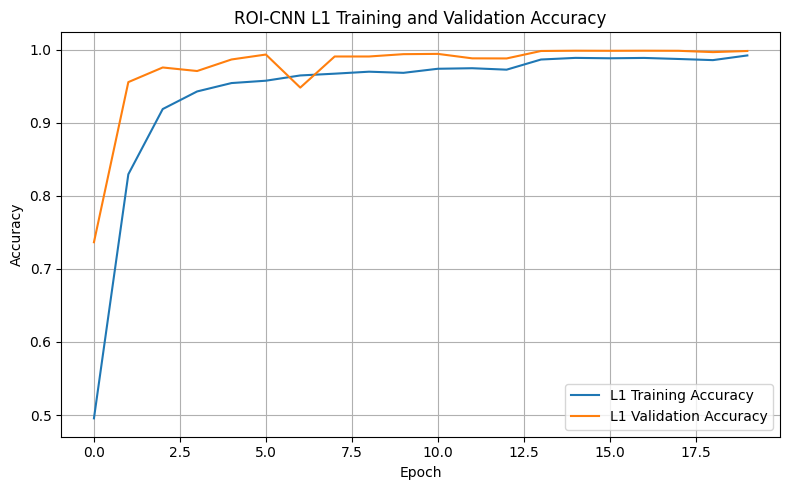

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    l1_history.history["accuracy"],
    label="L1 Training Accuracy"
)

plt.plot(
    l1_history.history["val_accuracy"],
    label="L1 Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ROI-CNN L1 Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

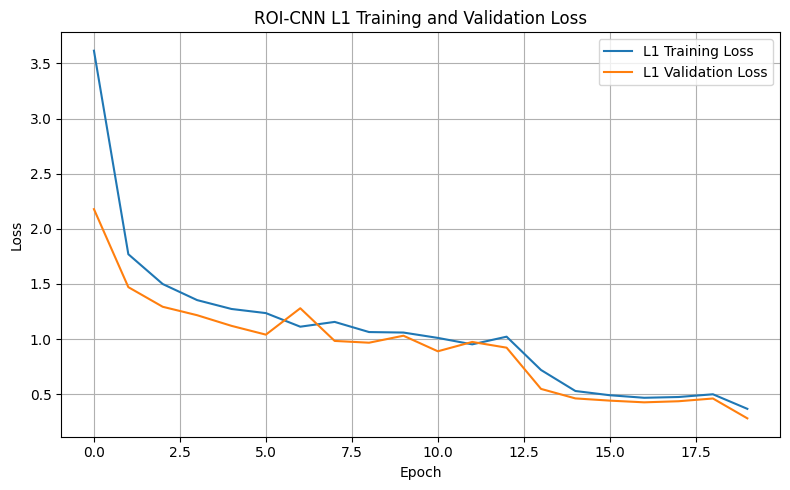

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    l1_history.history["loss"],
    label="L1 Training Loss"
)

plt.plot(
    l1_history.history["val_loss"],
    label="L1 Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ROI-CNN L1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
l2_train_acc = roi_history.history["accuracy"][-1]
l2_val_acc = roi_history.history["val_accuracy"][-1]
l2_train_loss = roi_history.history["loss"][-1]
l2_val_loss = roi_history.history["val_loss"][-1]

l1_train_acc = l1_history.history["accuracy"][-1]
l1_val_acc = l1_history.history["val_accuracy"][-1]
l1_train_loss = l1_history.history["loss"][-1]
l1_val_loss = l1_history.history["val_loss"][-1]

l2_accuracy_gap = l2_train_acc - l2_val_acc
l2_loss_gap = l2_val_loss - l2_train_loss

l1_accuracy_gap = l1_train_acc - l1_val_acc
l1_loss_gap = l1_val_loss - l1_train_loss

bias_variance_df = pd.DataFrame({
    "Model": ["ROI-CNN L2", "ROI-CNN L1"],
    "Training Accuracy": [l2_train_acc, l1_train_acc],
    "Validation Accuracy": [l2_val_acc, l1_val_acc],
    "Accuracy Gap": [l2_accuracy_gap, l1_accuracy_gap],
    "Training Loss": [l2_train_loss, l1_train_loss],
    "Validation Loss": [l2_val_loss, l1_val_loss],
    "Loss Gap": [l2_loss_gap, l1_loss_gap]
})

bias_variance_df

,Model,Training Accuracy,Validation Accuracy,Accuracy Gap,Training Loss,Validation Loss,Loss Gap
0,ROI-CNN L2,0.993337,0.998980,-0.005643,0.093669,0.074391,-0.019279
1,ROI-CNN L1,0.992253,0.998342,-0.006089,0.366612,0.280381,-0.086232


In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

cv_data = train_data.reset_index(drop=True)

X_cv = cv_data["Path"].values
y_cv = cv_data["ClassId"].values

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

folds = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cv, y_cv), 1):
    folds.append((train_idx, val_idx))
    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}"
    )

print("Total samples:", len(X_cv))
print("Number of folds:", len(folds))

Fold 1: Train = 20911, Validation = 10456
Fold 2: Train = 20911, Validation = 10456
Fold 3: Train = 20912, Validation = 10455
Total samples: 31367
Number of folds: 3


In [ ]:
cv_data = train_data.copy().reset_index(drop=True)

cv_data["Path"] = cv_data["Path"].apply(
    lambda x: "/content/GTSRB/" + x
)

print(cv_data["Path"].iloc[0])
print(tf.io.gfile.exists(cv_data["Path"].iloc[0]))

/content/GTSRB/Train/12/00012_00031_00018.png
True


In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
NUM_CLASSES = 43

def create_roi_dataset(data, shuffle=False):
    paths = data["image_path"].values
    labels = data["label"].values

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_image(image, channels=3, expand_animations=False)
        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        return image, tf.cast(label, tf.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(len(data))

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
model_cost_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "ROI-CNN L2",
        "ROI-CNN L1"
    ],
    "Total Parameters": [
        baseline_model.count_params(),
        roi_model.count_params(),
        l1_model.count_params()
    ],
    "Trainable Parameters": [
        np.sum([np.prod(v.shape) for v in baseline_model.trainable_variables]),
        np.sum([np.prod(v.shape) for v in roi_model.trainable_variables]),
        np.sum([np.prod(v.shape) for v in l1_model.trainable_variables])
    ],
    "Non-Trainable Parameters": [
        np.sum([np.prod(v.shape) for v in baseline_model.non_trainable_variables]),
        np.sum([np.prod(v.shape) for v in roi_model.non_trainable_variables]),
        np.sum([np.prod(v.shape) for v in l1_model.non_trainable_variables])
    ]
})

model_cost_df["Parameter Size (MB)"] = (
    model_cost_df["Total Parameters"] * 4 / (1024 ** 2)
)

model_cost_df

,Model,Total Parameters,Trainable Parameters,Non-Trainable Parameters,Parameter Size (MB)
0,Baseline CNN,2202603,2202155,456,8.402264
1,ROI-CNN L2,2202603,2202155,456,8.402264
2,ROI-CNN L1,2202603,2202155,456,8.402264


In [ ]:
import pandas as pd

co4_table = pd.DataFrame({
    "Method": [
        "CNN - Published",
        "ResNet50 - Published",
        "VGG19 - Published",
        "EfficientNetB7 - Published",
        "ConvNeSe - Published",
        "Our Baseline CNN",
        "Our ROI-CNN + L1",
        "Our ROI-CNN + L2"
    ],
    "Year": [
        2024, 2024, 2024, 2024, 2024, 2026, 2026, 2026
    ],
    "GTSRB Accuracy (%)": [
        99.25, 99.28, 98.95, 98.24, 99.85,
        97.7751, 98.2185, 98.5273
    ],
    "Parameters (M)": [
        None, None, None, None, 26.87,
        2.202603, 2.202603, 2.202603
    ],
    "Source": [
        "Assemlali & Sael, 2024",
        "Assemlali & Sael, 2024",
        "Assemlali & Sael, 2024",
        "Assemlali & Sael, 2024",
        "ConvNeSe, 2024",
        "Our experiment",
        "Our experiment",
        "Our experiment"
    ]
})

co4_table

,Method,Year,GTSRB Accuracy (%),Parameters (M),Source
0,CNN - Published,2024,99.2500,NaN,"Assemlali & Sael, 2024"
1,ResNet50 - Published,2024,99.2800,NaN,"Assemlali & Sael, 2024"
2,VGG19 - Published,2024,98.9500,NaN,"Assemlali & Sael, 2024"
3,EfficientNetB7 - Published,2024,98.2400,NaN,"Assemlali & Sael, 2024"
4,ConvNeSe - Published,2024,99.8500,26.870000,"ConvNeSe, 2024"
5,Our Baseline CNN,2026,97.7751,2.202603,Our experiment
6,Our ROI-CNN + L1,2026,98.2185,2.202603,Our experiment
7,Our ROI-CNN + L2,2026,98.5273,2.202603,Our experiment


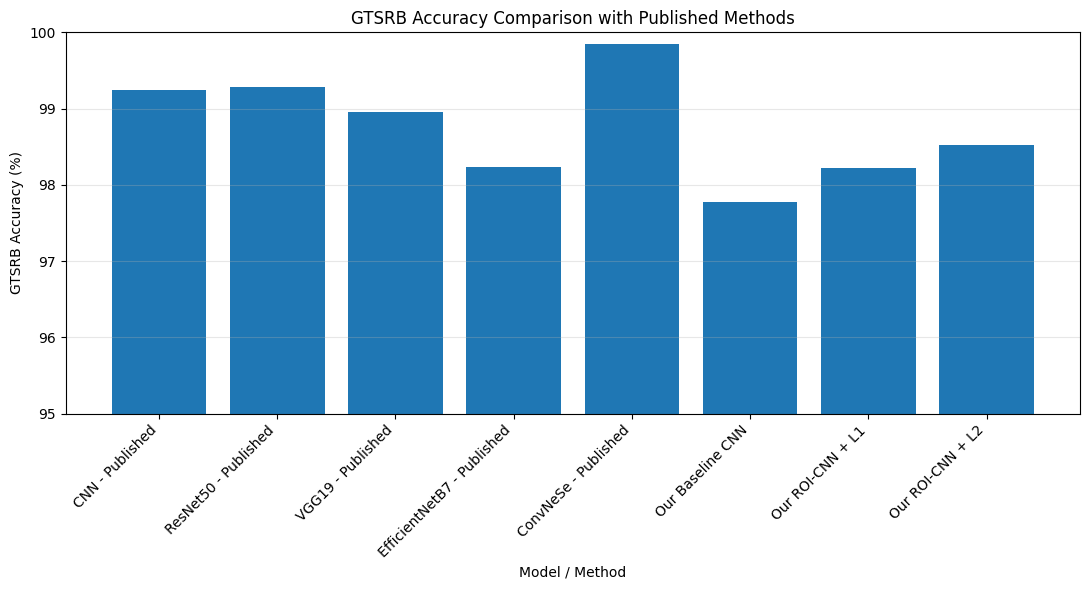

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    co4_table["Method"],
    co4_table["GTSRB Accuracy (%)"]
)

plt.xlabel("Model / Method")
plt.ylabel("GTSRB Accuracy (%)")
plt.title("GTSRB Accuracy Comparison with Published Methods")
plt.xticks(rotation=45, ha="right")
plt.ylim(95, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

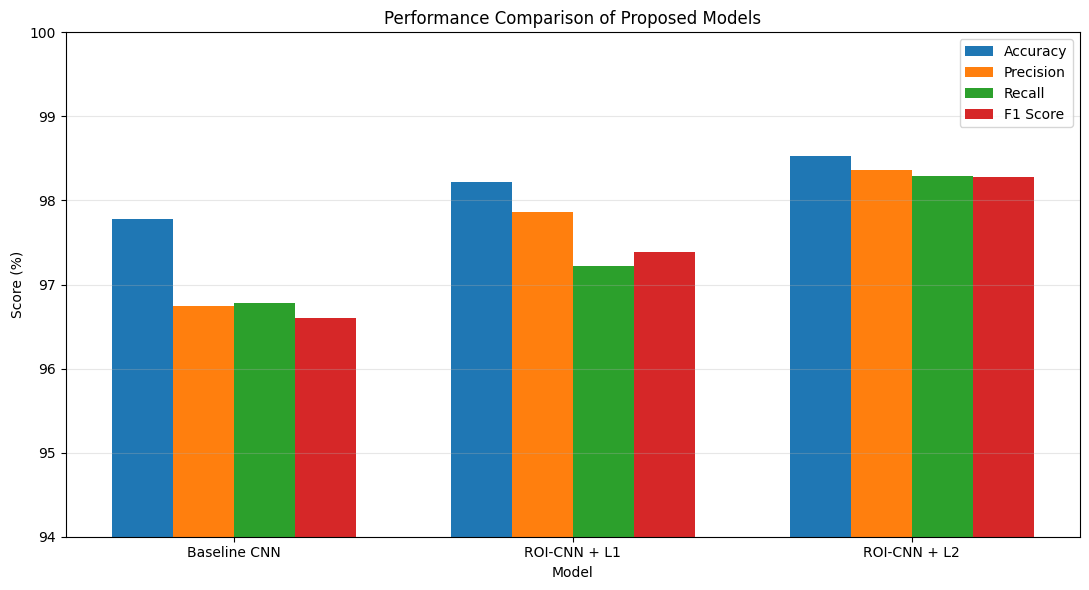

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Baseline CNN",
    "ROI-CNN + L1",
    "ROI-CNN + L2"
]

accuracy = [
    0.977751,
    0.982185,
    0.985273
]

precision = [
    0.967500,
    0.978652,
    0.983600
]

recall = [
    0.967800,
    0.972186,
    0.982926
]

f1 = [
    0.966000,
    0.973836,
    0.982780
]

x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(11, 6))

plt.bar(x - 1.5 * width, np.array(accuracy) * 100, width, label="Accuracy")
plt.bar(x - 0.5 * width, np.array(precision) * 100, width, label="Precision")
plt.bar(x + 0.5 * width, np.array(recall) * 100, width, label="Recall")
plt.bar(x + 1.5 * width, np.array(f1) * 100, width, label="F1 Score")

plt.xlabel("Model")
plt.ylabel("Score (%)")
plt.title("Performance Comparison of Proposed Models")
plt.xticks(x, models)
plt.ylim(94, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

baseline_results = {
    "Accuracy": 0.977751,
    "Precision": 0.967500,
    "Recall": 0.967800,
    "F1 Score": 0.966000,
    "Test Loss": 0.210401,
    "Parameters": 2202603
}

roi_l2_results = {
    "Accuracy": 0.985273,
    "Precision": 0.983600,
    "Recall": 0.982926,
    "F1 Score": 0.982780,
    "Test Loss": 0.143754,
    "Parameters": 2202603
}

roi_l1_results = {
    "Accuracy": 0.982185,
    "Precision": 0.978652,
    "Recall": 0.972186,
    "F1 Score": 0.973836,
    "Test Loss": 0.311423,
    "Parameters": 2202603
}

ablation_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Test Loss",
        "Parameters"
    ],
    "Baseline CNN": [
        baseline_results["Accuracy"] * 100,
        baseline_results["Precision"] * 100,
        baseline_results["Recall"] * 100,
        baseline_results["F1 Score"] * 100,
        baseline_results["Test Loss"],
        baseline_results["Parameters"]
    ],
    "ROI-CNN + L1": [
        roi_l1_results["Accuracy"] * 100,
        roi_l1_results["Precision"] * 100,
        roi_l1_results["Recall"] * 100,
        roi_l1_results["F1 Score"] * 100,
        roi_l1_results["Test Loss"],
        roi_l1_results["Parameters"]
    ],
    "ROI-CNN + L2": [
        roi_l2_results["Accuracy"] * 100,
        roi_l2_results["Precision"] * 100,
        roi_l2_results["Recall"] * 100,
        roi_l2_results["F1 Score"] * 100,
        roi_l2_results["Test Loss"],
        roi_l2_results["Parameters"]
    ]
})

ablation_table

,Metric,Baseline CNN,ROI-CNN + L1,ROI-CNN + L2
0,Accuracy,9.777510e+01,9.821850e+01,9.852730e+01
1,Macro Precision,9.675000e+01,9.786520e+01,9.836000e+01
2,Macro Recall,9.678000e+01,9.721860e+01,9.829260e+01
3,Macro F1,9.660000e+01,9.738360e+01,9.827800e+01
4,Test Loss,2.104010e-01,3.114230e-01,1.437540e-01
5,Parameters,2.202603e+06,2.202603e+06,2.202603e+06


In [ ]:
improvement_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Test Loss"
    ],
    "ROI-CNN + L2 Improvement": [
        (roi_l2_results["Accuracy"] - baseline_results["Accuracy"]) * 100,
        (roi_l2_results["Precision"] - baseline_results["Precision"]) * 100,
        (roi_l2_results["Recall"] - baseline_results["Recall"]) * 100,
        (roi_l2_results["F1 Score"] - baseline_results["F1 Score"]) * 100,
        roi_l2_results["Test Loss"] - baseline_results["Test Loss"]
    ]
})

improvement_table

,Metric,ROI-CNN + L2 Improvement
0,Accuracy,0.752200
1,Macro Precision,1.610000
2,Macro Recall,1.512600
3,Macro F1,1.678000
4,Test Loss,-0.066647


In [ ]:
master_results = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "ROI-CNN + L1",
        "ROI-CNN + L2"
    ],
    "Accuracy (%)": [
        97.7751,
        98.2185,
        98.5273
    ],
    "Macro Precision (%)": [
        96.7500,
        97.8652,
        98.3600
    ],
    "Macro Recall (%)": [
        96.7800,
        97.2186,
        98.2926
    ],
    "Macro F1 (%)": [
        96.6000,
        97.3836,
        98.2780
    ],
    "Macro Specificity (%)": [
        99.9465,
        99.9571,
        99.9644
    ],
    "Macro ROC-AUC (%)": [
        99.9851,
        99.9942,
        99.9955
    ],
    "Test Loss": [
        0.210401,
        0.311423,
        0.143754
    ],
    "Parameters": [
        2202603,
        2202603,
        2202603
    ]
})

display(
    master_results.style.format({
        "Accuracy (%)": "{:.2f}",
        "Macro Precision (%)": "{:.2f}",
        "Macro Recall (%)": "{:.2f}",
        "Macro F1 (%)": "{:.2f}",
        "Macro Specificity (%)": "{:.2f}",
        "Macro ROC-AUC (%)": "{:.2f}",
        "Test Loss": "{:.4f}",
        "Parameters": "{:,.0f}"
    })
)

,Model,Accuracy (%),Macro Precision (%),Macro Recall (%),Macro F1 (%),Macro Specificity (%),Macro ROC-AUC (%),Test Loss,Parameters
0,Baseline CNN,97.78,96.75,96.78,96.60,99.95,99.99,0.2104,"2,202,603"
1,ROI-CNN + L1,98.22,97.87,97.22,97.38,99.96,99.99,0.3114,"2,202,603"
2,ROI-CNN + L2,98.53,98.36,98.29,98.28,99.96,100.00,0.1438,"2,202,603"


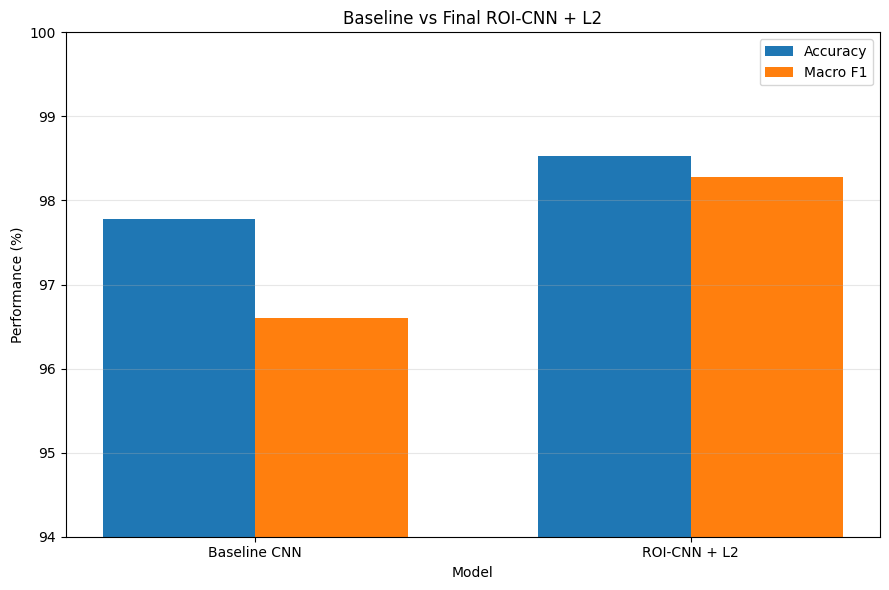

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Baseline CNN", "ROI-CNN + L2"]

accuracy = [97.7751, 98.5273]
f1_score = [96.6000, 98.2780]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(x - width / 2, accuracy, width, label="Accuracy")
plt.bar(x + width / 2, f1_score, width, label="Macro F1")

plt.xlabel("Model")
plt.ylabel("Performance (%)")
plt.title("Baseline vs Final ROI-CNN + L2")
plt.xticks(x, models)
plt.ylim(94, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()